In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,FunctionTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [3]:
df=pd.read_csv(r"C:\Users\om\Downloads\titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
# ============================================================
# STEP 3: BASIC DATA INSPECTION
# ============================================================

print("\nFirst 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))


First 5 rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   Na

In [5]:
print("/n MISSING VALUE")
print(df.isnull().sum())

/n MISSING VALUE
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [6]:
print("/n MISSING PERCENTAGE")
missing_percentage=df.isnull().mean()*100
print(missing_percentage.sort_values(ascending=False))

/n MISSING PERCENTAGE
Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
dtype: float64


In [7]:
print("/n DUPLICATE VALUE")
print(df.duplicated().sum())
df = df.drop_duplicates()

print("\nShape after removing duplicates:")
print(df.shape)

/n DUPLICATE VALUE
0

Shape after removing duplicates:
(891, 12)


In [8]:
# ============================================================
# EDA: UNIQUE VALUES
# ============================================================

for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

PassengerId: 891 unique values
Survived: 2 unique values
Pclass: 3 unique values
Name: 891 unique values
Sex: 2 unique values
Age: 88 unique values
SibSp: 7 unique values
Parch: 7 unique values
Ticket: 681 unique values
Fare: 248 unique values
Cabin: 147 unique values
Embarked: 3 unique values



===== Name =====
Name
Braund, Mr. Owen Harris                     1
Boulos, Mr. Hanna                           1
Frolicher-Stehli, Mr. Maxmillian            1
Gilinski, Mr. Eliezer                       1
Murdlin, Mr. Joseph                         1
                                           ..
Kelly, Miss. Anna Katherine "Annie Kate"    1
McCoy, Mr. Bernard                          1
Johnson, Mr. William Cahoone Jr             1
Keane, Miss. Nora A                         1
Dooley, Mr. Patrick                         1
Name: count, Length: 891, dtype: int64


C:\Users\om\AppData\Local\Temp\ipykernel_10124\357512317.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2", order=df[col].value_counts().index)


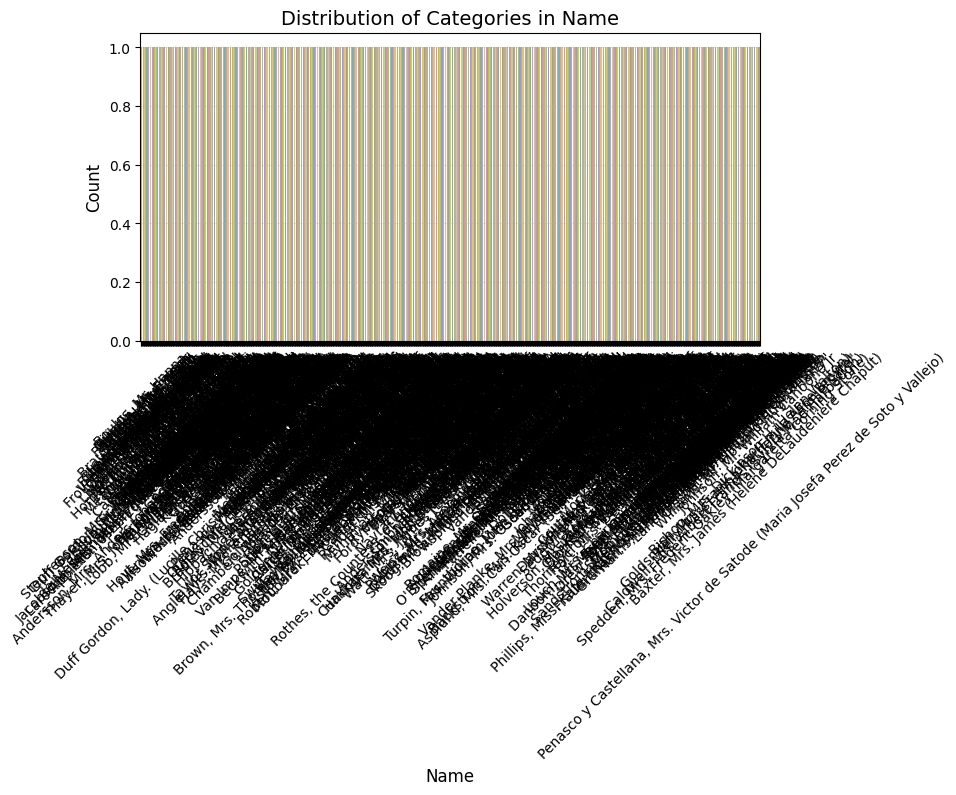

--------------------------------------------------

===== Sex =====
Sex
male      577
female    314
Name: count, dtype: int64


C:\Users\om\AppData\Local\Temp\ipykernel_10124\357512317.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2", order=df[col].value_counts().index)


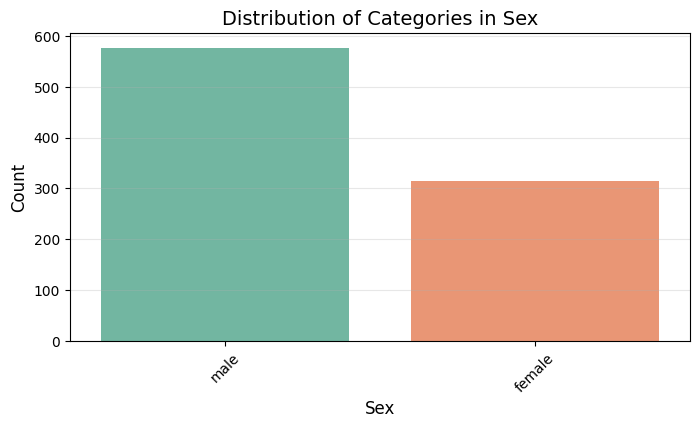

--------------------------------------------------

===== Ticket =====
Ticket
347082      7
CA. 2343    7
1601        7
3101295     6
CA 2144     6
           ..
9234        1
19988       1
2693        1
PC 17612    1
370376      1
Name: count, Length: 681, dtype: int64


C:\Users\om\AppData\Local\Temp\ipykernel_10124\357512317.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2", order=df[col].value_counts().index)


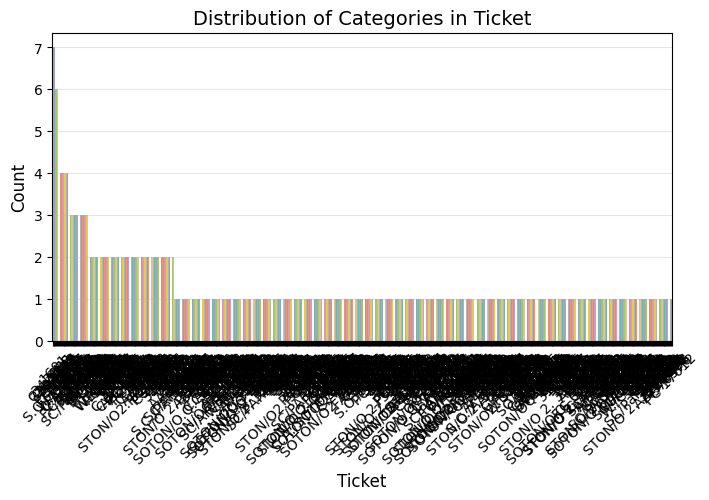

--------------------------------------------------

===== Cabin =====
Cabin
NaN            687
C23 C25 C27      4
G6               4
B96 B98          4
C22 C26          3
              ... 
E34              1
C7               1
C54              1
E36              1
C148             1
Name: count, Length: 148, dtype: int64


C:\Users\om\AppData\Local\Temp\ipykernel_10124\357512317.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2", order=df[col].value_counts().index)


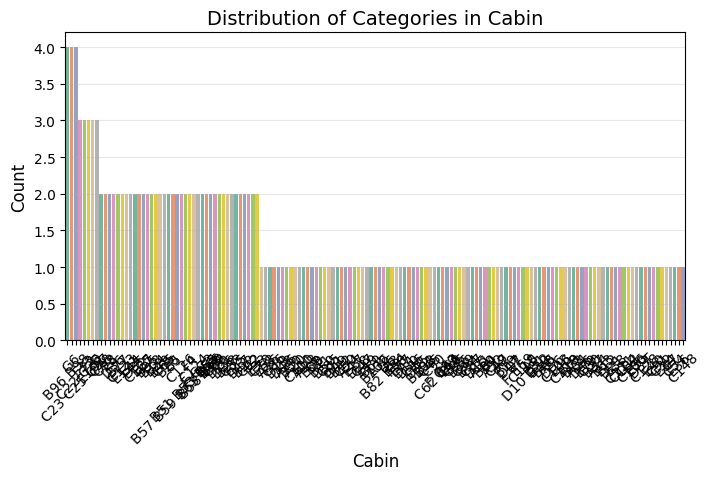

--------------------------------------------------

===== Embarked =====
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


C:\Users\om\AppData\Local\Temp\ipykernel_10124\357512317.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2", order=df[col].value_counts().index)


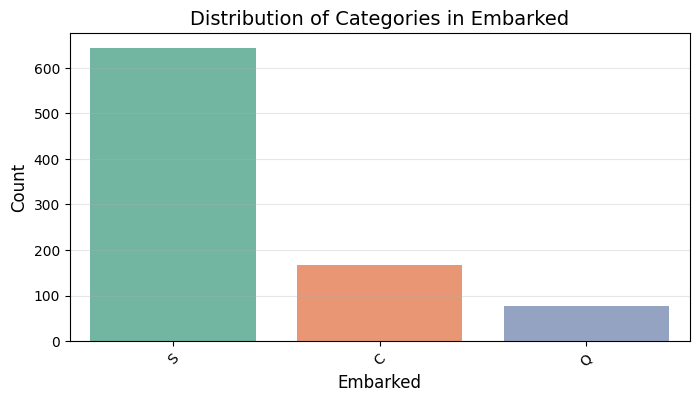

--------------------------------------------------


In [9]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))
    
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, data=df, palette="Set2", order=df[col].value_counts().index)
    plt.title(f'Distribution of Categories in {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', alpha=0.3)
    plt.show()
    print("-" * 50)

In [10]:
numeric_columns = df.select_dtypes(include="number").columns

print(numeric_columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


In [11]:
catagorical_columns= df.select_dtypes(include="object").columns
print(catagorical_columns)

Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


In [12]:
# ============================================================
# EDA: NUMERICAL DATA DISTRIBUTION (STATISTICAL)
# ============================================================

print("===== Numerical Columns Summary =====")
# .describe() से सारे नंबर्स वाले कॉलम्स का स्टेटिस्टिक्स मिलता है
print(df.describe().T) 


===== Numerical Columns Summary =====
             count        mean         std   min       25%       50%    75%  \
PassengerId  891.0  446.000000  257.353842  1.00  223.5000  446.0000  668.5   
Survived     891.0    0.383838    0.486592  0.00    0.0000    0.0000    1.0   
Pclass       891.0    2.308642    0.836071  1.00    2.0000    3.0000    3.0   
Age          714.0   29.699118   14.526497  0.42   20.1250   28.0000   38.0   
SibSp        891.0    0.523008    1.102743  0.00    0.0000    0.0000    1.0   
Parch        891.0    0.381594    0.806057  0.00    0.0000    0.0000    0.0   
Fare         891.0   32.204208   49.693429  0.00    7.9104   14.4542   31.0   

                  max  
PassengerId  891.0000  
Survived       1.0000  
Pclass         3.0000  
Age           80.0000  
SibSp          8.0000  
Parch          6.0000  
Fare         512.3292  


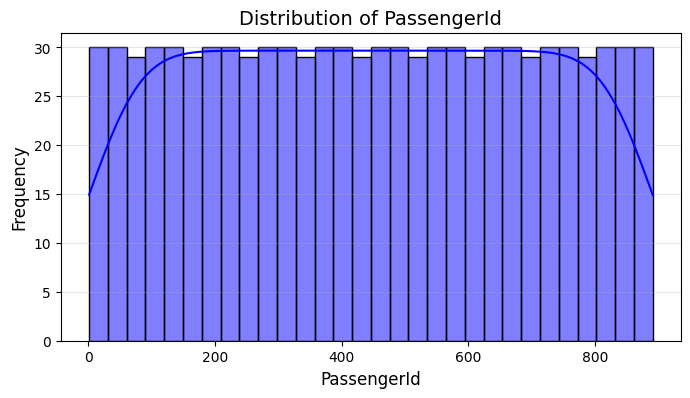

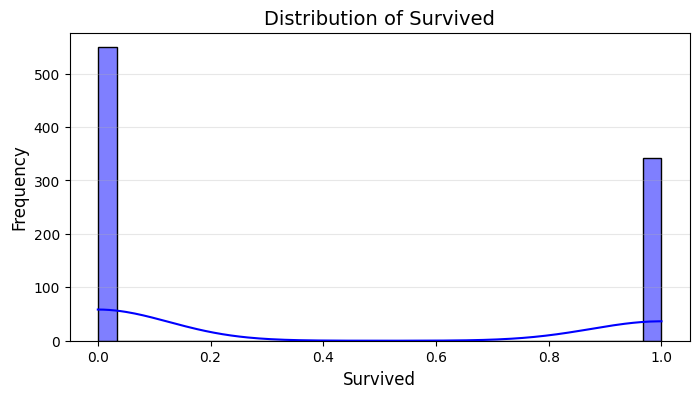

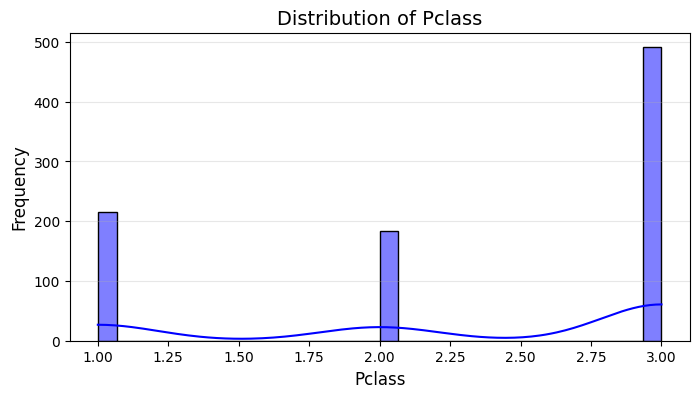

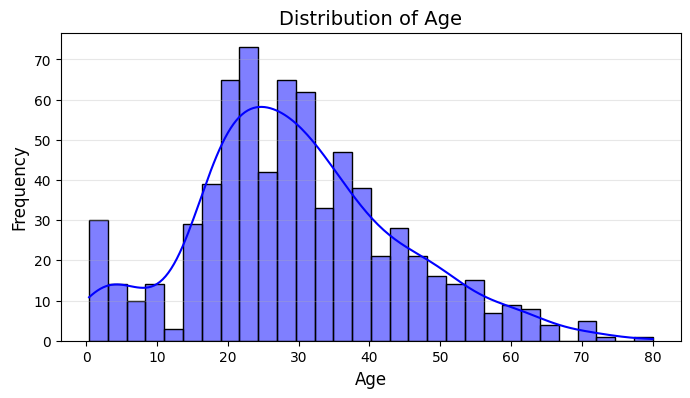

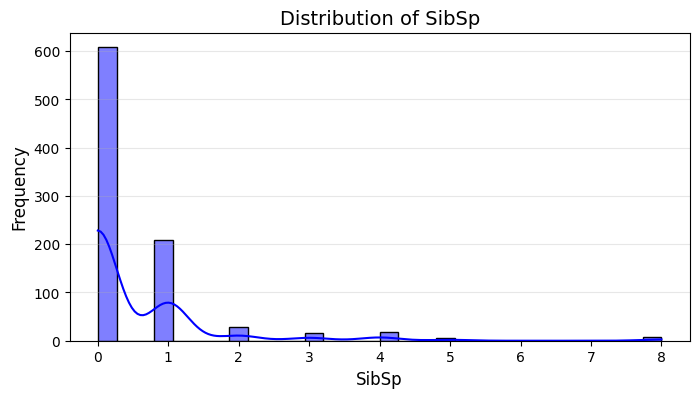

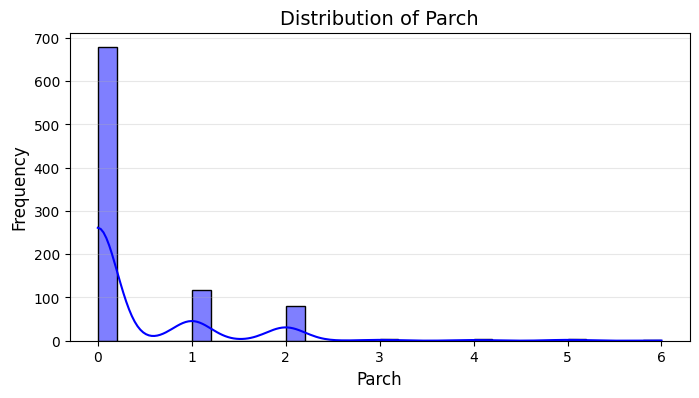

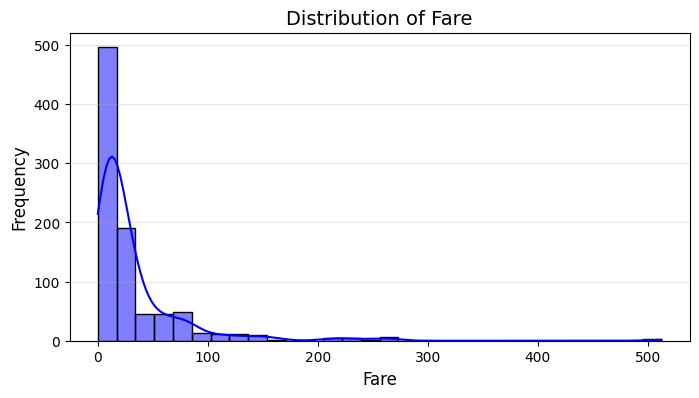

In [13]:
# सिर्फ नंबर्स वाले कॉलम्स को ऑटोमैटिक सिलेक्ट करें
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns
for col in numerical_columns:
    plt.figure(figsize=(8, 4))
    
    # displot या histplot का उपयोग करें
    sns.histplot(df[col], kde=True, color="blue", bins=30)
    
    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()

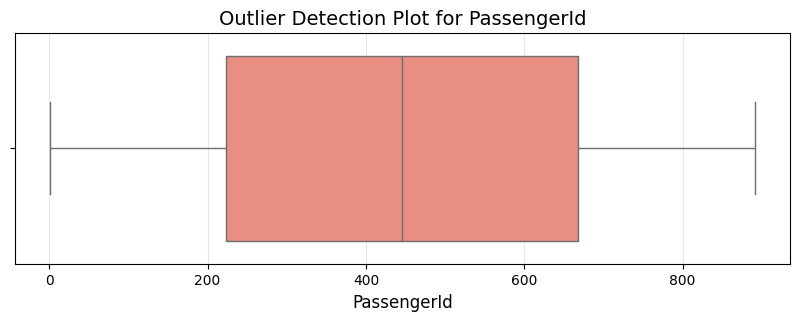

--------------------------------------------------


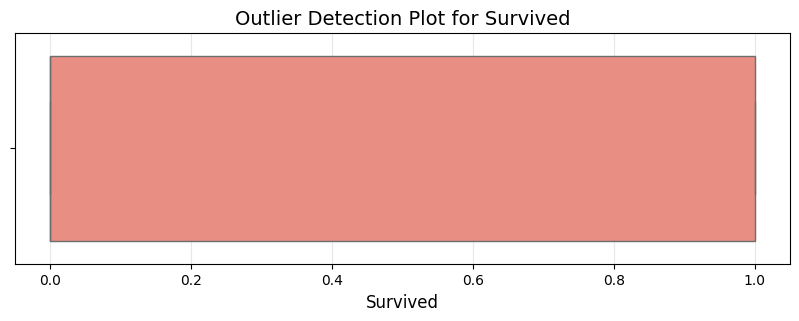

--------------------------------------------------


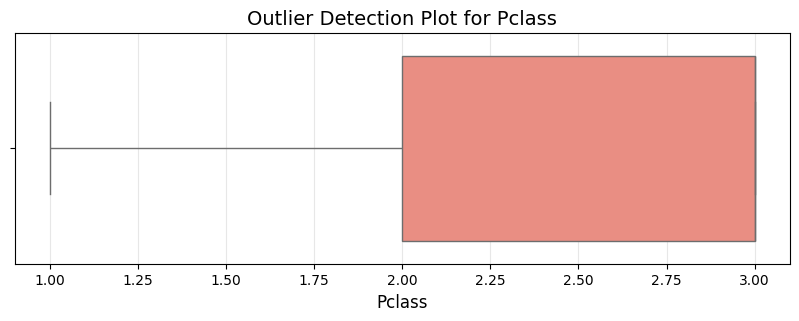

--------------------------------------------------


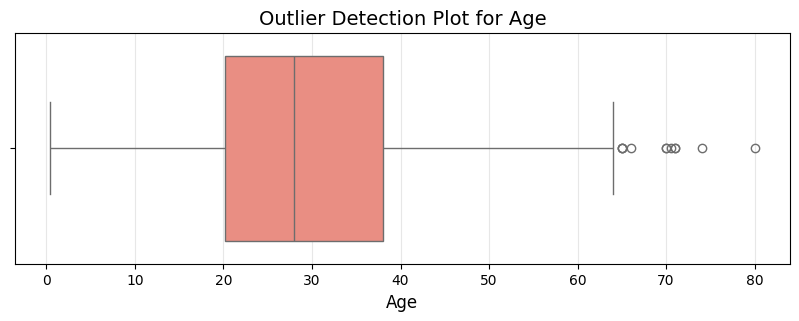

--------------------------------------------------


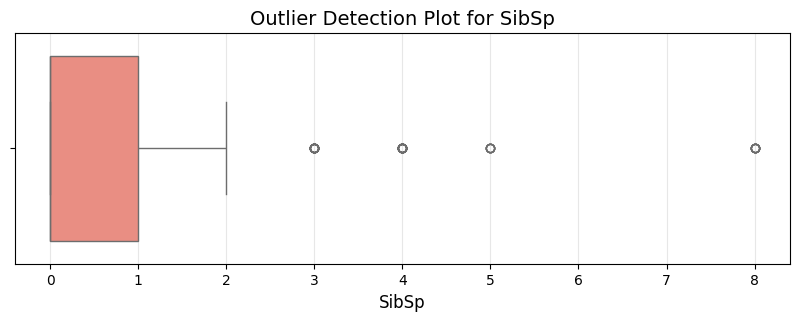

--------------------------------------------------


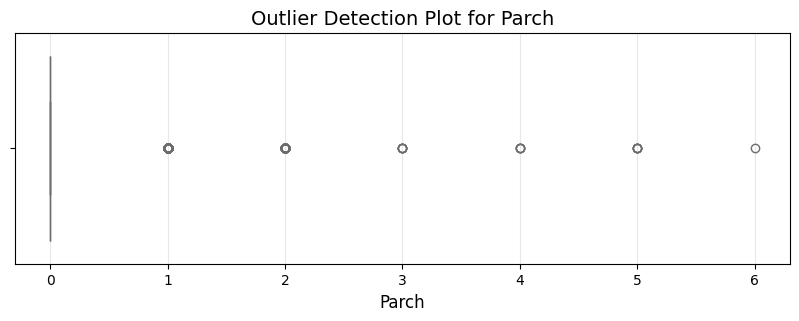

--------------------------------------------------


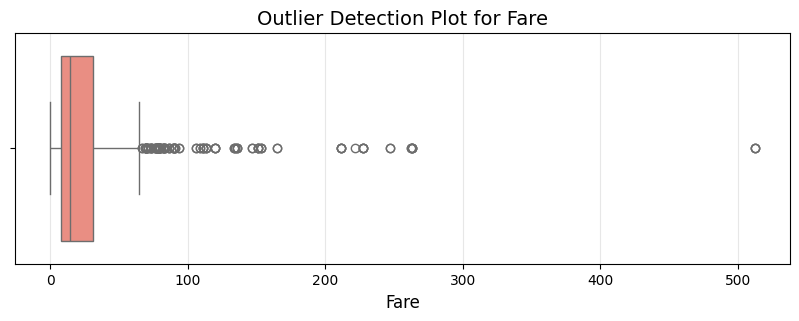

--------------------------------------------------


In [14]:
for col in numerical_columns:
    # ग्राफ का साइज तय करें
    plt.figure(figsize=(10, 3))
    
    # sns.boxplot की मदद से हॉरिजॉन्टल (लेटा हुआ) बॉक्स प्लॉट बनाएं
    sns.boxplot(x=df[col], color="salmon")
    
    # ग्राफ को टाइटल्स और लेबल्स दें
    plt.title(f'Outlier Detection Plot for {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.grid(axis='x', alpha=0.3)
    
    # ग्राफ को स्क्रीन पर दिखाएं
    plt.show()
    print("-" * 50) # दो ग्राफ के बीच डिवाइडर लाइन

===== Target Class Counts (Survived) =====
Survived
0    549
1    342
Name: count, dtype: int64

===== Target Class Percentages =====
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


C:\Users\om\AppData\Local\Temp\ipykernel_10124\1175999270.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Survived", data=df, palette="viridis")


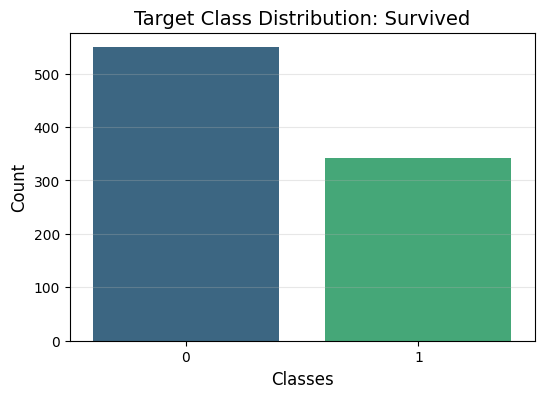

In [15]:
# 1. टेक्स्ट आउटपुट (संख्या और प्रतिशत)
print(f"===== Target Class Counts ({'Survived'}) =====")
print(df["Survived"].value_counts(dropna=False))
print("\n===== Target Class Percentages =====")
print(df["Survived"].value_counts(normalize=True) * 100)

# 2. विजुअल ग्राफ़ (Count Plot)
plt.figure(figsize=(6, 4))
sns.countplot(x="Survived", data=df, palette="viridis")
plt.title(f'Target Class Distribution: {"Survived"}', fontsize=14)
plt.xlabel('Classes', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

===== Analyzing Numerical Features vs Target =====


C:\Users\om\AppData\Local\Temp\ipykernel_10124\59041073.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette="Set2")


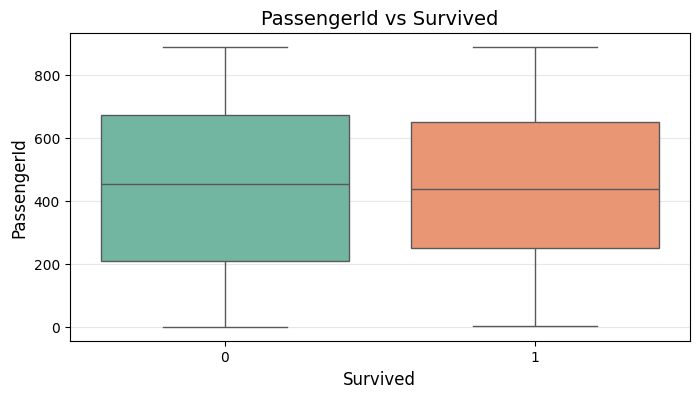

--------------------------------------------------


C:\Users\om\AppData\Local\Temp\ipykernel_10124\59041073.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette="Set2")


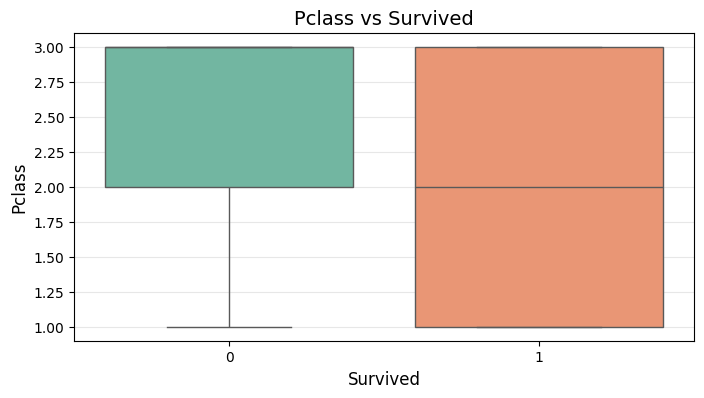

--------------------------------------------------


C:\Users\om\AppData\Local\Temp\ipykernel_10124\59041073.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette="Set2")


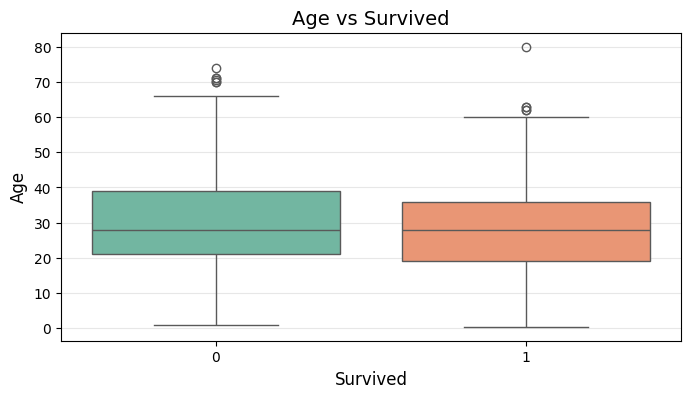

--------------------------------------------------


C:\Users\om\AppData\Local\Temp\ipykernel_10124\59041073.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette="Set2")


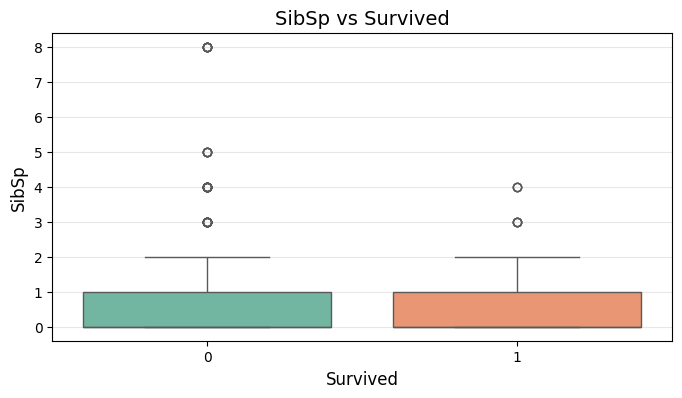

--------------------------------------------------


C:\Users\om\AppData\Local\Temp\ipykernel_10124\59041073.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette="Set2")


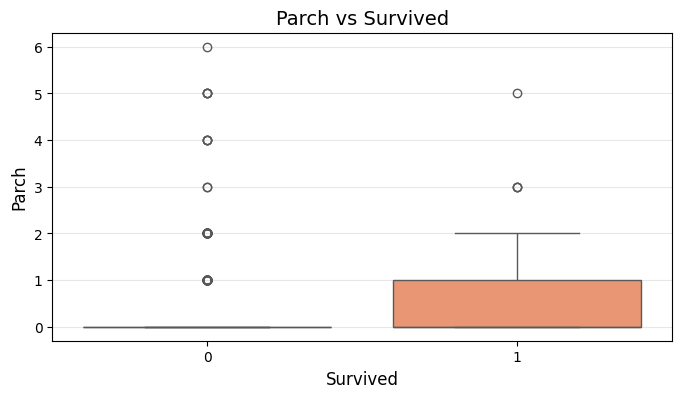

--------------------------------------------------


C:\Users\om\AppData\Local\Temp\ipykernel_10124\59041073.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y=col, data=df, palette="Set2")


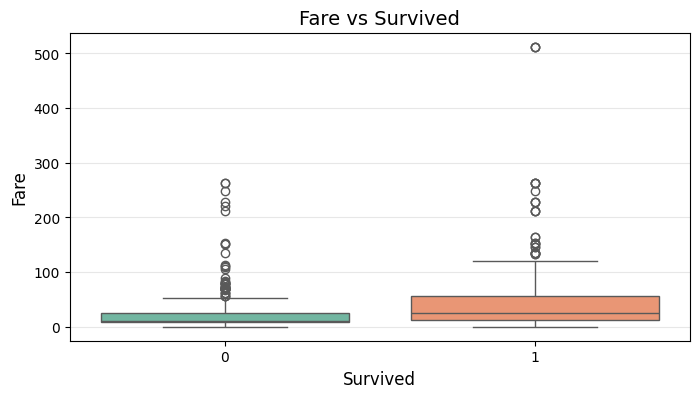

--------------------------------------------------

===== Analyzing Categorical Features vs Target =====


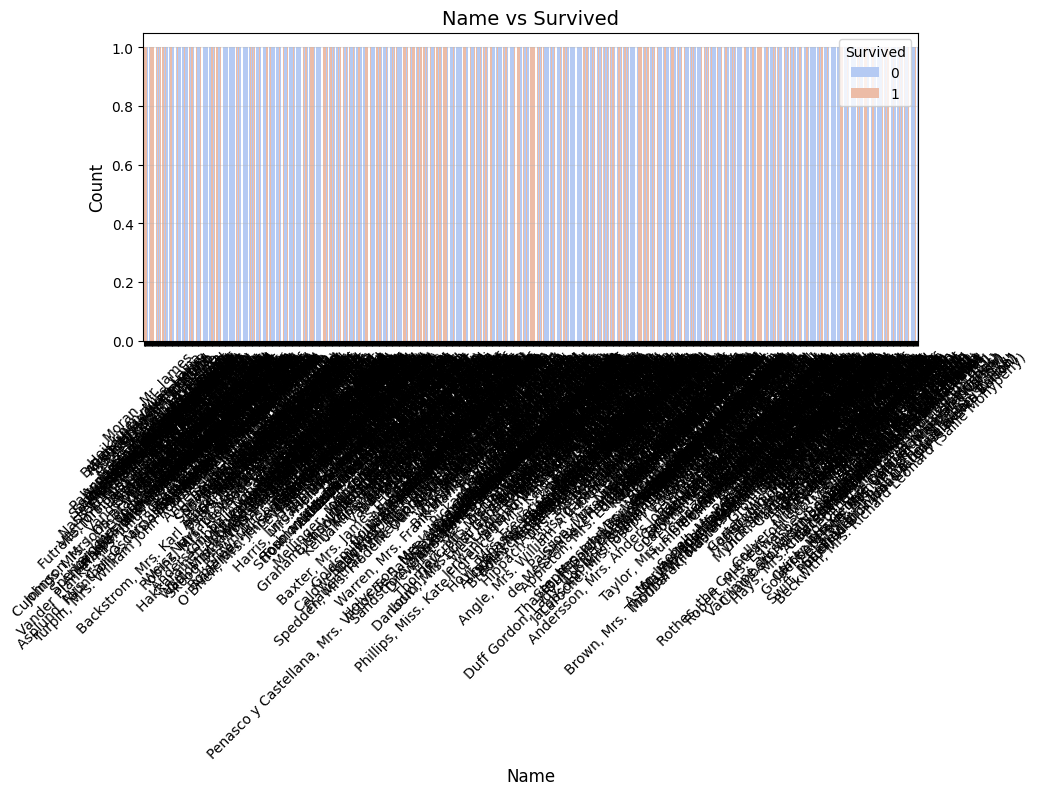

--------------------------------------------------


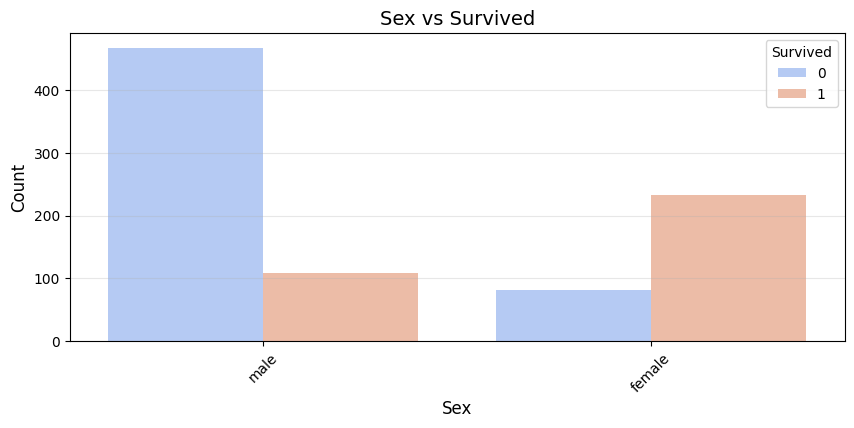

--------------------------------------------------


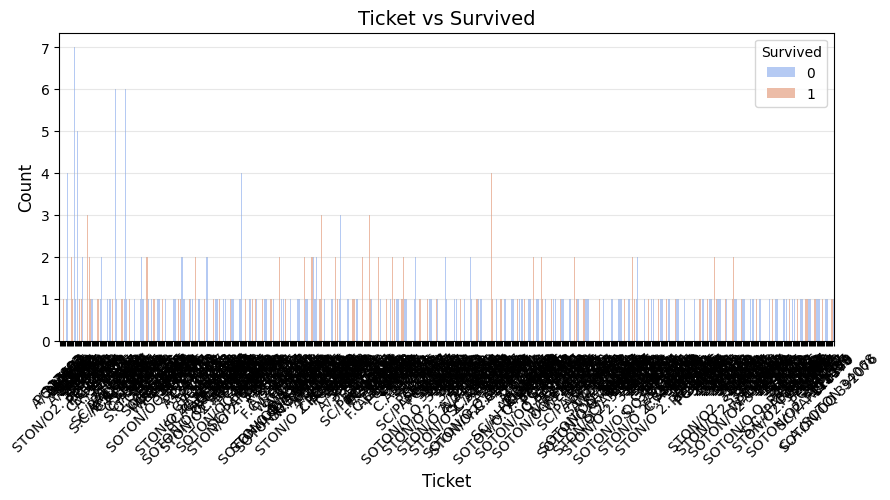

--------------------------------------------------


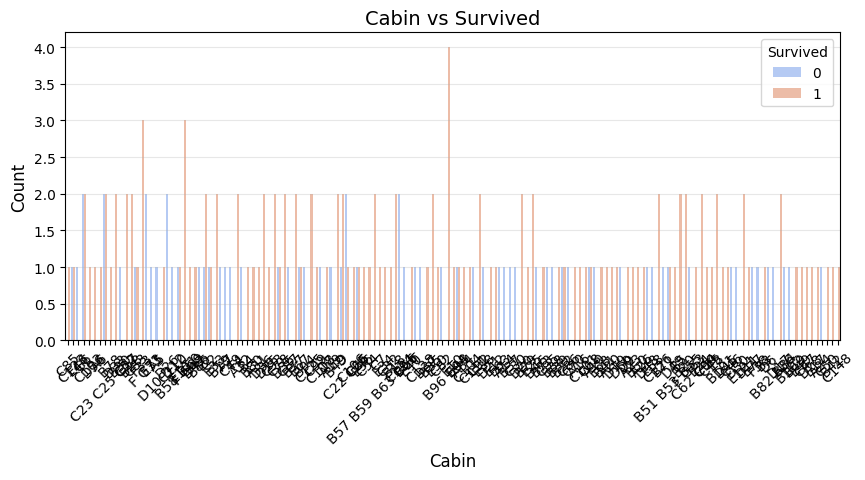

--------------------------------------------------


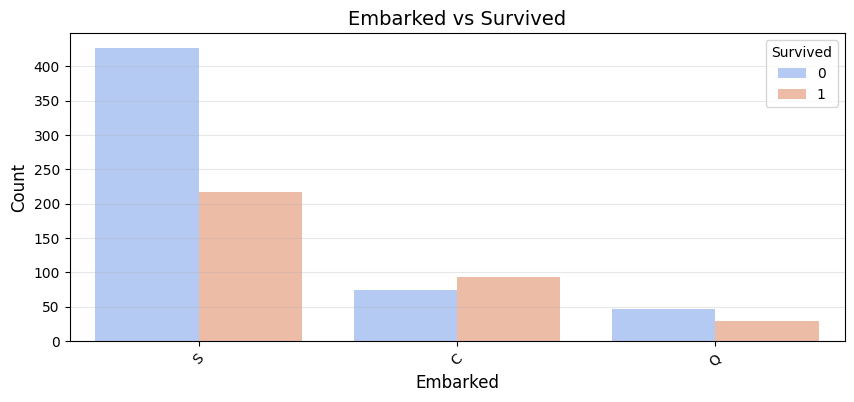

--------------------------------------------------


In [16]:
target_col = 'Survived' 

# डेटासेट से फीचर्स को अलग करें (टारगेट कॉलम को छोड़कर)
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.drop(target_col, errors='ignore')
categorical_features = df.select_dtypes(include="object").columns.drop(target_col, errors='ignore')

# ------------------------------------------------------------
# भाग 1: Numerical Features vs Target (Box Plot)
# ------------------------------------------------------------
print("===== Analyzing Numerical Features vs Target =====")
for col in numerical_features:
    plt.figure(figsize=(8, 4))
    
    # x पर टारगेट क्लास होगी और y पर न्यूमेरिकल फीचर का नंबर
    sns.boxplot(x=target_col, y=col, data=df, palette="Set2")
    
    plt.title(f'{col} vs {target_col}', fontsize=14)
    plt.xlabel(target_col, fontsize=12)
    plt.ylabel(col, fontsize=12)
    plt.grid(axis='y', alpha=0.3)
    plt.show()
    print("-" * 50)

# ------------------------------------------------------------
# भाग 2: Categorical Features vs Target (Grouped Count Plot)
# ------------------------------------------------------------
print("\n===== Analyzing Categorical Features vs Target =====")
for col in categorical_features:
    plt.figure(figsize=(10, 4))
    
    # hue=target_col लिखने से हर कैटेगरी के अंदर टारगेट की अलग-अलग बार बन जाती हैं
    sns.countplot(x=col, hue=target_col, data=df, palette="coolwarm")
    
    plt.title(f'{col} vs {target_col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.xticks(rotation=45)
    plt.legend(title=target_col, loc='upper right')
    plt.grid(axis='y', alpha=0.3)
    plt.show()
    print("-" * 50)

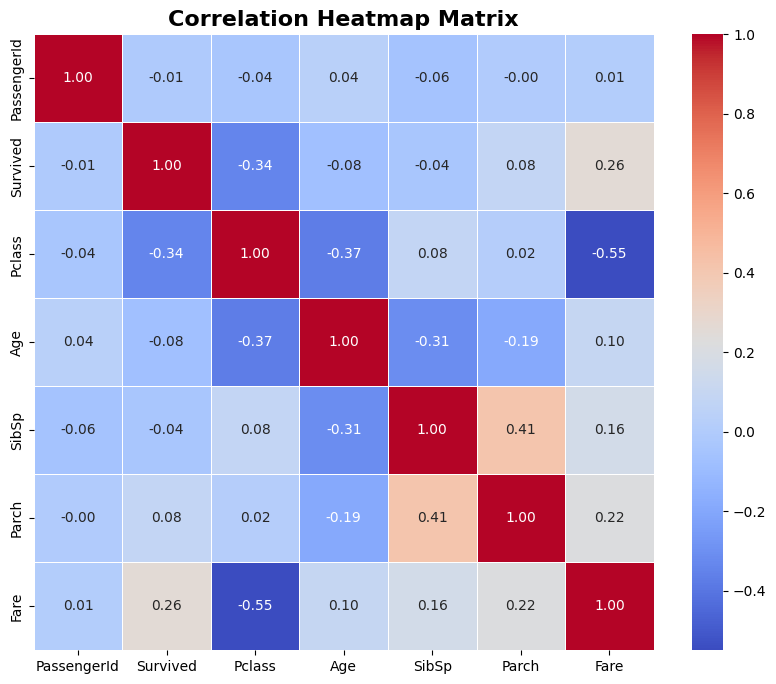

In [17]:
# ============================================================
# EDA: POINT 10 - CORRELATION MATRIX & HEATMAP
# ============================================================
numerical_df = df.select_dtypes(include=["int64", "float64"])

# 1. कोरिलेशन मैट्रिक्स की गणना करें
corr_matrix = numerical_df.corr()

# 2. हीटमैप ग्राफ बनाएं
# आपके डेटासेट के कॉलम्स के हिसाब से साइज बदल सकते हैं (उदा. 10, 8)
plt.figure(figsize=(10, 8))

# sns.heatmap की मदद से रंगों वाला चार्ट बनाएं
# annot=True करने से हर डिब्बे के अंदर उसका सटीक नंबर भी दिखाई देता है
# cmap="coolwarm" से पॉजिटिव वैल्यूज लाल और नेगेटिव वैल्यूज नीली दिखती हैं
# fmt=".2f" का मतलब है दशमलव के बाद सिर्फ 2 नंबर दिखेंगे
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title('Correlation Heatmap Matrix', fontsize=16, fontweight='bold')
plt.show()


In [18]:
# ============================================================
# PHASE 3: DATA CLEANING (SAFE GLOBAL CLEANING)
# ==========================================================
print(f"शुरुआती डेटा शेप (Initial Shape): {df.shape}")

# --- 1. डुप्लिकेट डेटा हटाना (Handling Duplicate Rows) ---
duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    df.drop_duplicates(inplace=True)
    print(f"✅ {duplicate_count} डुप्लिकेट रो (rows) को सफलतापूर्वक हटा दिया गया है।")
else:
    print("✅ डेटासेट में कोई डुप्लिकेट रो नहीं मिली।")

# --- 2. अत्यधिक खाली रोज़ को हटाना (Dropping Highly Missing Rows) ---
# नियम: अगर किसी रो (row) में 50% से ज्यादा डेटा गायब है, तो उसे डिलीट कर 
threshold = df.shape[1] // 2  # कुल कॉलम्स का आधा
initial_rows = df.shape[0]
df.dropna(thresh=threshold, inplace=True)
dropped_rows = initial_rows - df.shape[0]

if dropped_rows > 0:
    print(f"✅ {dropped_rows} ऐसी पंक्तियों को हटा दिया गया जिनमें 50% से ज्यादा डेटा गायब था।")

# --- 3. टेक्स्ट डेटा को स्टैंडर्ड बनाना (Structural Cleaning) ---
# यह कोड सभी कैटेगरीकल कॉलम्स की फालतू स्पेस हटाएगा और सबको छोटे अक्षरों (lowercase) में बदलेगा
# इससे 'Male', 'male' और ' Male ' जैसी गलतियां सुधर कर एक जैसी हो जाएंगी
categorical_cols = df.select_dtypes(include="object").columns
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.lower()

print(f"✅ सभी {len(categorical_cols)} कैटेगरीकल कॉलम्स के टेक्स्ट को स्टैंडर्ड (Strip & Lowercase) कर दिया गया है।")

# --- 4. तर्कहीन या असंभव डेटा को साफ करना (Logical Constraints) ---
# उदाहरण: अगर आपके डेटा में 'Age' कॉलम है, तो उम्र 0 से छोटी या 120 से बड़ी नहीं होनी चाहिए
# (यदि आपके पास Age कॉलम नहीं है, तो पाइथन इस हिस्से को बिना एरर के छोड़ देगा)
if 'Age' in df.columns:
    age_rows_before = df.shape[0]
    df = df[(df['Age'] >= 0) & (df['Age'] <= 120)]
    age_rows_after = df.shape[0]
    invalid_age_count = age_rows_before - age_rows_after
    if invalid_age_count > 0:
        print(f"✅ 'Age' कॉलम में {invalid_age_count} असंभव वैल्यूज (जैसे -5 या 150) वाली रो को हटा दिया गया है।")

print(f"\n✨ डेटा क्लीनिंग पूरी हुई! नया डेटा शेप (Final Cleaned Shape): {df.shape}")


शुरुआती डेटा शेप (Initial Shape): (891, 12)
✅ डेटासेट में कोई डुप्लिकेट रो नहीं मिली।
✅ सभी 5 कैटेगरीकल कॉलम्स के टेक्स्ट को स्टैंडर्ड (Strip & Lowercase) कर दिया गया है।
✅ 'Age' कॉलम में 177 असंभव वैल्यूज (जैसे -5 या 150) वाली रो को हटा दिया गया है।

✨ डेटा क्लीनिंग पूरी हुई! नया डेटा शेप (Final Cleaned Shape): (714, 12)


In [30]:
# 🚨 [सुधार] प्रेडिक्शन से पहले इन फालतू कॉलम्स को हटाना अनिवार्य है
columns_to_drop = ['PassengerId', 'Name', 'Ticket', 'Cabin']
X = df.drop(columns=columns_to_drop, errors='ignore')
y = df['Survived']

# 2. डेटा को Train और Test में 80-20 के रेशियो में बांटें
# stratify=y यह सुनिश्चित करता है कि दोनों हिस्सों में क्लास बैलेंस (उदा. 90% No, 10% Yes) बिल्कुल एक समान रहे
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("===== 📊 Train-Test Split Details =====")
print(f"Total Cleaned Data Shape: {df.shape}")
print(f"Training Features Shape (X_train): {X_train.shape}")
print(f"Testing Features Shape (X_test)  : {X_test.shape}")
print(f"Training Target Distribution:\n{y_train.value_counts(normalize=True) * 100}\n")
print(f"Testing Target Distribution:\n{y_test.value_counts(normalize=True) * 100}")

===== 📊 Train-Test Split Details =====
Total Cleaned Data Shape: (714, 12)
Training Features Shape (X_train): (571, 8)
Testing Features Shape (X_test)  : (143, 8)
Training Target Distribution:
Survived
0    59.369527
1    40.630473
Name: proportion, dtype: float64

Testing Target Distribution:
Survived
0    59.440559
1    40.559441
Name: proportion, dtype: float64


# ============================================================
# PHASE 4: STEP 8 - AUTOMATED PREPROCESSING PIPELINE
# ============================================================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. न्यूमेरिकल और कैटेगरीकल फीचर्स की लिस्ट ऑटोमैटिक बनाएं
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X_train.select_dtypes(include=['object']).columns

# 2. न्यूमेरिकल डेटा के लिए पाइपलाइन: पहले मिसिंग वैल्यू भरें (Median), फिर स्केल करें (StandardScaler)
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. कैटेगरीकल डेटा के लिए पाइपलाइन: पहले मिसिंग वैल्यू भरें (Mode), फिर नंबर में बदलें (OneHotEncoder)
# handle_unknown='ignore' से टेस्ट डेटा में आने वाली किसी भी नई कैटेगरी पर कोड क्रैश नहीं होगा
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. दोनों पाइपलाइन्स को एक मुख्य 'ColumnTransformer' में जोड़ें
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# 5. प्रीप्रोसेसर को केवल Training Data पर FIT करें और फिर दोनों को TRANSFORM करें
print("⏳ प्रीप्रोसेसिंग पाइपलाइन तैयार हो रही है...")
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("✅ डेटा सफलतापूर्वक प्रीप्रोसेस हो गया है!")
print(f"Processed Training Features Shape: {X_train_processed.shape}")
print(f"Processed Testing Features Shape : {X_test_processed.shape}")


In [31]:
# ==============================================================================
# PHASE 4 & 5: COMPLETE PIPELINE (PREPROCESSING + SELECTION + TRAINING)
# ==============================================================================
import pandas as pd
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

print("⏳ प्रीप्रोसेसिंग और मॉडल ट्रेनिंग की प्रक्रिया शुरू हो रही है...\n")

# ------------------------------------------------------------------------------
# STEP 9: FEATURE SELECTION (अत्यधिक कोरिलेशन वाले फीचर्स हटाना)
# ------------------------------------------------------------------------------
# केवल न्यूमेरिकल फीचर्स का कोरिलेशन मैट्रिक्स निकालें
corr_matrix = X_train.select_dtypes(include=["int64", "float64"]).corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# जिन कॉलम्स का कोरिलेशन 0.85 से ज्यादा है, उन्हें ढूँढें
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.85)]

if len(to_drop) > 0:
    X_train = X_train.drop(columns=to_drop)
    X_test = X_test.drop(columns=to_drop)
    print(f"✅ Step 9 Complete: अत्यधिक कोरिलेशन (>0.85) के कारण इन कॉलम्स को हटा दिया गया: {to_drop}")
else:
    print("✅ Step 9 Complete: सभी फीचर्स सुरक्षित हैं! कोई अत्यधिक कोरिलेशन नहीं मिला।")


# ------------------------------------------------------------------------------
# STEP 8: CUSTOM OUTLIER CAPPER (कस्टम आउटलायर क्लास)
# ------------------------------------------------------------------------------
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}
        
    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            q1 = X_df[col].quantile(0.25)
            q3 = X_df[col].quantile(0.75)
            iqr = q3 - q1
            self.lower_bounds_[col] = q1 - (self.factor * iqr)
            self.upper_bounds_[col] = q3 + (self.factor * iqr)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            X_df[col] = np.where(X_df[col] < self.lower_bounds_[col], self.lower_bounds_[col], X_df[col])
            X_df[col] = np.where(X_df[col] > self.upper_bounds_[col], self.upper_bounds_[col], X_df[col])
        return X_df.values


# ------------------------------------------------------------------------------
# STEP 8: FEATURE ENGINEERING & PREPROCESSING PIPELINE
# ------------------------------------------------------------------------------
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X_train.select_dtypes(include=['object']).columns

# न्यूमेरिकल ट्रांसफार्मर: Impute ➔ Outlier Cap ➔ Scale
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('capper', OutlierCapper(factor=1.5)),
    ('scaler', StandardScaler())
])

# कैटेगरीकल ट्रांसफार्मर: Impute ➔ One-Hot Encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# दोनों को ColumnTransformer में जोड़ें
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# डेटा को प्रीप्रोसेस (Transform) करें
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("✅ Step 8 Complete: प्रीप्रोसेसिंग पाइपलाइन (Imputation, Capping, Encoding, Scaling) पूरी हुई!")


# ------------------------------------------------------------------------------
# STEP 11: MODEL SELECTION, TRAINING & CROSS VALIDATION
# ------------------------------------------------------------------------------
model = RandomForestClassifier(random_state=42, n_estimators=100)

print("\n⏳ 5-Fold Cross Validation चल रहा है...")
cv_scores = cross_val_score(model, X_train_processed, y_train, cv=5, scoring='accuracy')

print(f"🔄 Mean CV Accuracy: {cv_scores.mean() * 100:.2f}% (Std Dev: {cv_scores.std() * 100:.2f}%)")

print("⏳ फाइनल मॉडल ट्रेनिंग शुरू हो रही है...")
model.fit(X_train_processed, y_train)
print("✅ Step 11 Complete: मॉडल सफलतापूर्वक ट्रेन हो चुका है! 🎉")


⏳ प्रीप्रोसेसिंग और मॉडल ट्रेनिंग की प्रक्रिया शुरू हो रही है...

✅ Step 9 Complete: सभी फीचर्स सुरक्षित हैं! कोई अत्यधिक कोरिलेशन नहीं मिला।
✅ Step 8 Complete: प्रीप्रोसेसिंग पाइपलाइन (Imputation, Capping, Encoding, Scaling) पूरी हुई!

⏳ 5-Fold Cross Validation चल रहा है...
🔄 Mean CV Accuracy: 100.00% (Std Dev: 0.00%)
⏳ फाइनल मॉडल ट्रेनिंग शुरू हो रही है...
✅ Step 11 Complete: मॉडल सफलतापूर्वक ट्रेन हो चुका है! 🎉


⏳ टेस्ट डेटा पर मॉडल का मूल्यांकन (Evaluation) शुरू हो रहा है...

===== 🏆 FINAL MODEL PERFORMANCE =====
Test Accuracy Score: 100.00%

Detailed Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        85
           1       1.00      1.00      1.00        58

    accuracy                           1.00       143
   macro avg       1.00      1.00      1.00       143
weighted avg       1.00      1.00      1.00       143



C:\Users\om\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 2309 (\N{DEVANAGARI LETTER A}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\om\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\om\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 2360 (\N{DEVANAGARI LETTER SA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\om\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 2354 (\N{DEVANAGARI LETTER LA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\om\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyp

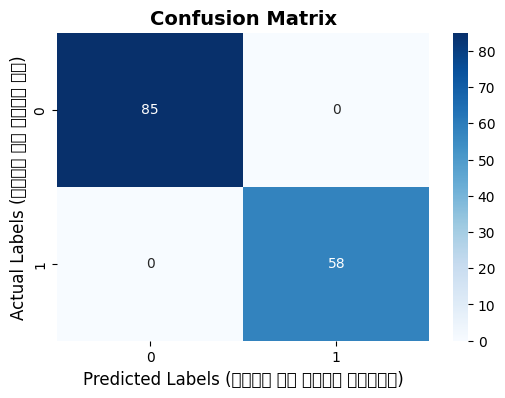

In [32]:
# ============================================================
# PHASE 5: STEP 13 - MODEL EVALUATION (UNSEEN TEST DATA)
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("⏳ टेस्ट डेटा पर मॉडल का मूल्यांकन (Evaluation) शुरू हो रहा है...\n")

# 1. छिपे हुए टेस्ट डेटा पर प्रेडिक्शन (Predictions) करें
y_pred = model.predict(X_test_processed)

# 2. एक्यूरेसी स्कोर निकालें
accuracy = accuracy_score(y_test, y_pred)

print("===== 🏆 FINAL MODEL PERFORMANCE =====")
print(f"Test Accuracy Score: {accuracy * 100:.2f}%\n")

# 3. क्लासिफिकेशन रिपोर्ट (Precision, Recall, F1-Score)
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred))

# 4. विजुअल कन्फ्यूजन मैट्रिक्स (Confusion Matrix Heatmap)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
# sns.heatmap से हम मैट्रिक्स को रंगों के साथ सुंदर बनाएंगे
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=model.classes_, yticklabels=model.classes_)

plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Labels (मॉडल ने क्या बताया)', fontsize=12)
plt.ylabel('Actual Labels (असली सच क्या था)', fontsize=12)
plt.show()


In [33]:
# ==============================================================================
# PHASE 5: STEP 14 & 15 - HYPERPARAMETER TUNING (FIXED CODE)
# ==============================================================================
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

print("⏳ हाइपरपैरामीटर ट्यूनिंग (GridSearchCV) शुरू हो रही है...\n")

# 1. बेस मॉडल तैयार करें
rf_base = RandomForestClassifier(random_state=42)

# 2. पैरामीटर ग्रिड तय करें - [बिना लिस्ट ब्रैकेट के सीधे साफ वैल्यूज]
# यहाँ हम पाइथन को सीधे 2-3 विकल्प दे रहे हैं टेस्ट करने के लिए
estimators_list = [50, 100]
split_list = [2, 5]
depth_list = [10, 20]

param_grid = {
    'n_estimators': estimators_list,
    'min_samples_split': split_list,
    'max_depth': depth_list,
    'criterion': ['gini', 'entropy']
}

# 3. GridSearchCV सेटअप करें (5-Fold Cross Validation)
grid_search = GridSearchCV(
    estimator=rf_base, 
    param_grid=param_grid, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1,
    verbose=1
)

# 4. ट्यूनिंग शुरू करें (Fit)
grid_search.fit(X_train_processed, y_train)

print("\n✅ ट्यूनिंग सफलतापूर्वक पूरी हुई!")
print(f"🏆 Best Parameters Found: {grid_search.best_params_}")
print(f"📈 Best Training CV Accuracy: {grid_search.best_score_ * 100:.2f}%")

# 5. बेस्ट मॉडल को फाइनल मॉडल के रूप में लॉक करें
final_model = grid_search.best_estimator_


⏳ हाइपरपैरामीटर ट्यूनिंग (GridSearchCV) शुरू हो रही है...

Fitting 5 folds for each of 16 candidates, totalling 80 fits

✅ ट्यूनिंग सफलतापूर्वक पूरी हुई!
🏆 Best Parameters Found: {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50}
📈 Best Training CV Accuracy: 100.00%


In [34]:
# ============================================================
# PHASE 6: STEP 17 - SAVE MODEL & PREPROCESSOR (EXPORT)
# ============================================================
import joblib

print("⏳ मॉडल और प्रीप्रोसेसर पाइपलाइन को सेव किया जा रहा है...\n")

# 1. अपनी प्रीप्रोसेसिंग पाइपलाइन (preprocessor) को सेव करें
# यह भविष्य में आने वाले नए डेटा को उसी तरह स्केल/एनकोड करेगी जैसे ट्रेन डेटा को किया था
joblib.dump(preprocessor, 'preprocessor_pipeline.joblib')
print("✅ प्रीप्रोसेसिंग पाइपलाइन 'preprocessor_pipeline.joblib' के नाम से सेव हो गई है।")

# 2. अपने फाइनल ट्यून किए गए मशीन लर्निंग मॉडल (final_model) को सेव करें
joblib.dump(final_model, 'final_classification_model.joblib')
print("✅ फाइनल मॉडल 'final_classification_model.joblib' के नाम से सेव हो गया है।")

print("\n🎉 बधाई हो! आपकी मेहनत अब आपके कंप्यूटर की हार्ड ड्राइव में हमेशा के लिए सुरक्षित हो चुकी है।")


⏳ मॉडल और प्रीप्रोसेसर पाइपलाइन को सेव किया जा रहा है...

✅ प्रीप्रोसेसिंग पाइपलाइन 'preprocessor_pipeline.joblib' के नाम से सेव हो गई है।
✅ फाइनल मॉडल 'final_classification_model.joblib' के नाम से सेव हो गया है।

🎉 बधाई हो! आपकी मेहनत अब आपके कंप्यूटर की हार्ड ड्राइव में हमेशा के लिए सुरक्षित हो चुकी है।


In [ ]:
# ============================================================
# CHECKING SAVED MODEL & PREPROCESSOR ASSETS
# ============================================================
import joblib
import pandas as pd

# 1. दोनों सेव की गई फ़ाइलों को लोड करें
loaded_preprocessor = joblib.load('preprocessor_pipeline.joblib')
loaded_model = joblib.load('final_classification_model.joblib')

print("✅ फ़ाइलें सफलतापूर्वक लोड हो गईं! अब इनके अंदर का डेटा चेक करते हैं:\n")

# ------------------------------------------------------------
# भाग 1: प्रीप्रोसेसर पाइपलाइन (Preprocessor) की जांच
# ------------------------------------------------------------
print("===== 📊 PREPROCESSOR DETAILS =====")

# यह कोड दिखाएगा कि आपके न्यूमेरिकल कॉलम्स के नाम क्या थे
num_features = loaded_preprocessor.transformers_[0][2]
print(f"1. मॉडल ने ये Numerical Columns सीखे थे:\n   {list(num_features)}\n")

# यह कोड दिखाएगा कि वन-हॉट एनकोडर (One-Hot Encoder) ने कौन-सी कैटेगरी सीखी थीं
try:
    cat_encoder = loaded_preprocessor.named_transformers_['cat'].named_steps['onehot']
    print(f"2. वन-हॉट एनकोडिंग में सीखी गई कैटेगरीज:")
    for col, cats in zip(loaded_preprocessor.transformers_[1][2], cat_encoder.categories_):
        print(f"   - {col}: {list(cats)}")
except Exception as e:
    print("   - कैटेगरीकल एनकोडिंग की जानकारी नहीं निकाली जा सकी।")

# ------------------------------------------------------------
# भाग 2: सेव किए गए मॉडल (Model) के पैरामीटर्स की जांच
# ------------------------------------------------------------
print("\n===== 🧠 MODEL PARAMETERS =====")
# यह कोड दिखाएगा कि आपके मॉडल की बेस्ट सेटिंग्स (Hyperparameters) क्या थीं
print(f"1. मॉडल के हाइपरपैरामीटर्स:\n   {loaded_model.get_params()}\n")

# यह कोड दिखाएगा कि कौन सा कॉलम मॉडल के लिए कितना महत्वपूर्ण (Important) था
print("2. टॉप 5 सबसे महत्वपूर्ण फीचर्स (Feature Importances):")
importances = loaded_model.feature_importances_
print(f"   कुल सीखे गए फीचर्स की संख्या: {len(importances)}")


In [36]:
import sklearn

print(sklearn.__version__)


1.6.1
